# Importing packages and data

The dataset itself ('heart_2020_cleaned.csv') must be uploaded to Colab.

Analyze the shape of the dataset and its values. Extract numerical and categorical features.

In [1]:
!pip install fairlearn

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import missingno as msno
from scipy import stats

In [3]:
original_df = pd.read_csv('../content/heart_2020_cleaned.csv')
df = original_df.copy()

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns}")


for col in df.columns:
  print(f"{col}: {df[col].dtype}, {df[col].unique()}")

numeric_features=['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
categorical_features=['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking', 'Sex', 'AgeCategory',
       'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth','Asthma', 'KidneyDisease', 'SkinCancer']

df[numeric_features] = df[numeric_features].apply(pd.to_numeric, errors='coerce')

Shape: (319795, 18)
Columns: Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'DiffWalking', 'Sex', 'AgeCategory',
       'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'SleepTime',
       'Asthma', 'KidneyDisease', 'SkinCancer'],
      dtype='object')
HeartDisease: object, ['No' 'Yes']
BMI: float64, [16.6  20.34 26.58 ... 62.42 51.46 46.56]
Smoking: object, ['Yes' 'No']
AlcoholDrinking: object, ['No' 'Yes']
Stroke: object, ['No' 'Yes']
PhysicalHealth: float64, [ 3.  0. 20. 28.  6. 15.  5. 30.  7.  1.  2. 21.  4. 10. 14. 18.  8. 25.
 16. 29. 27. 17. 24. 12. 23. 26. 22. 19.  9. 13. 11.]
MentalHealth: float64, [30.  0.  2.  5. 15.  8.  4.  3. 10. 14. 20.  1.  7. 24.  9. 28. 16. 12.
  6. 25. 17. 18. 21. 29. 22. 13. 23. 27. 26. 11. 19.]
DiffWalking: object, ['No' 'Yes']
Sex: object, ['Female' 'Male']
AgeCategory: object, ['55-59' '80 or older' '65-69' '75-79' '40-44' '70-74' '60-64' '50-54'
 '45-49' '18-24' '35-39' '30-34'

# Analyze distribution of data

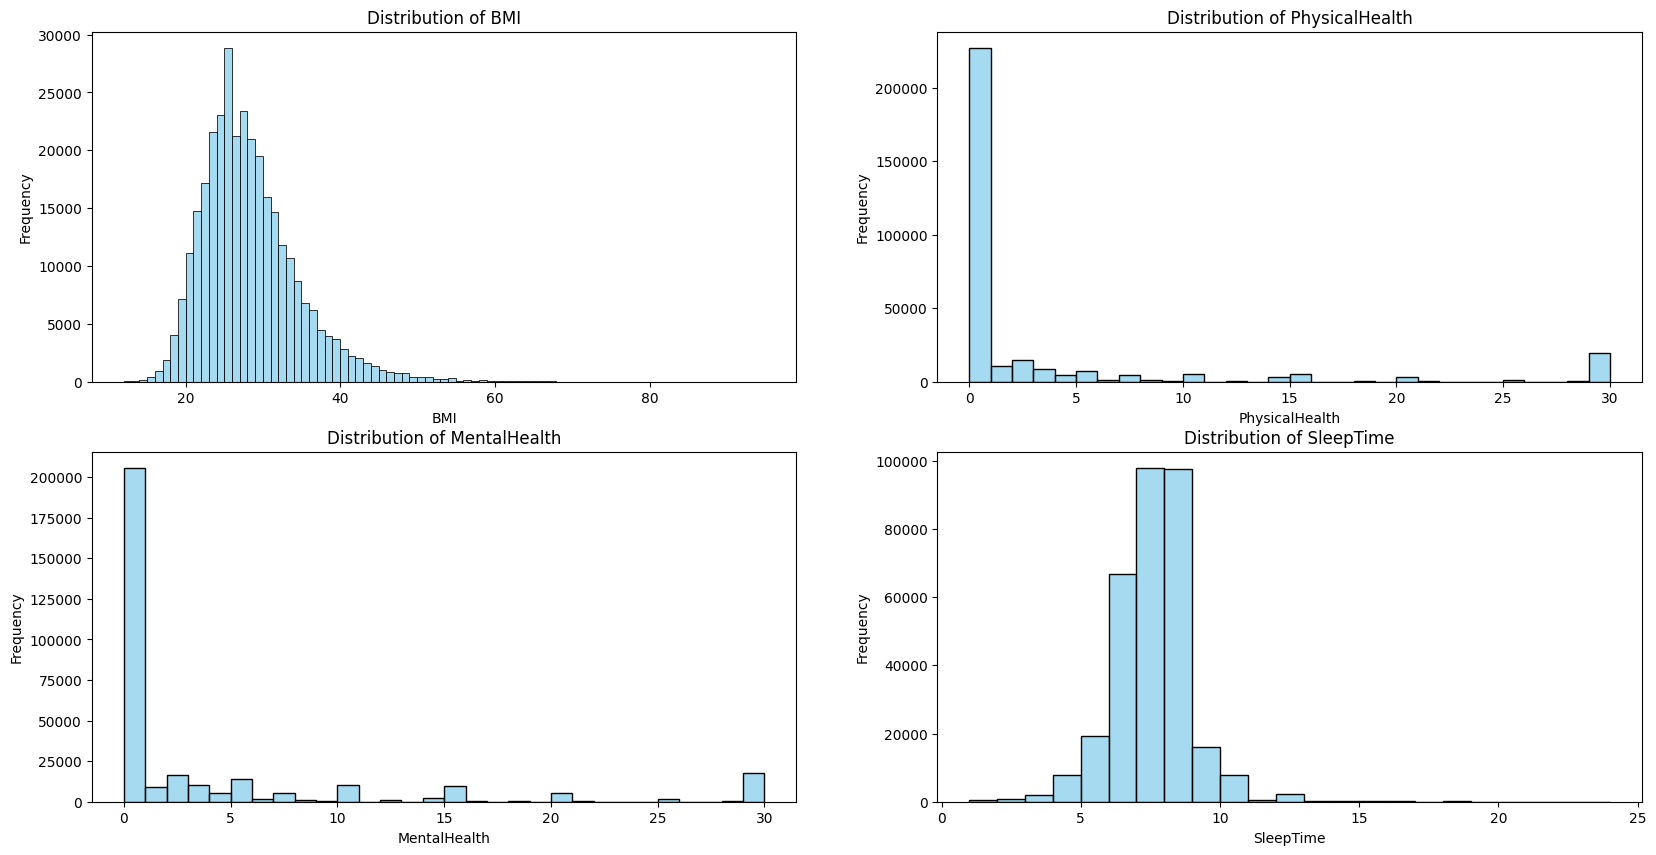

In [4]:
fig, axes = plt.subplots(2, len(numeric_features)//2, figsize=(20, 10))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.histplot(data=df, x=feature, bins=30, binwidth=1, kde=False, color='skyblue', ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

plt.show()

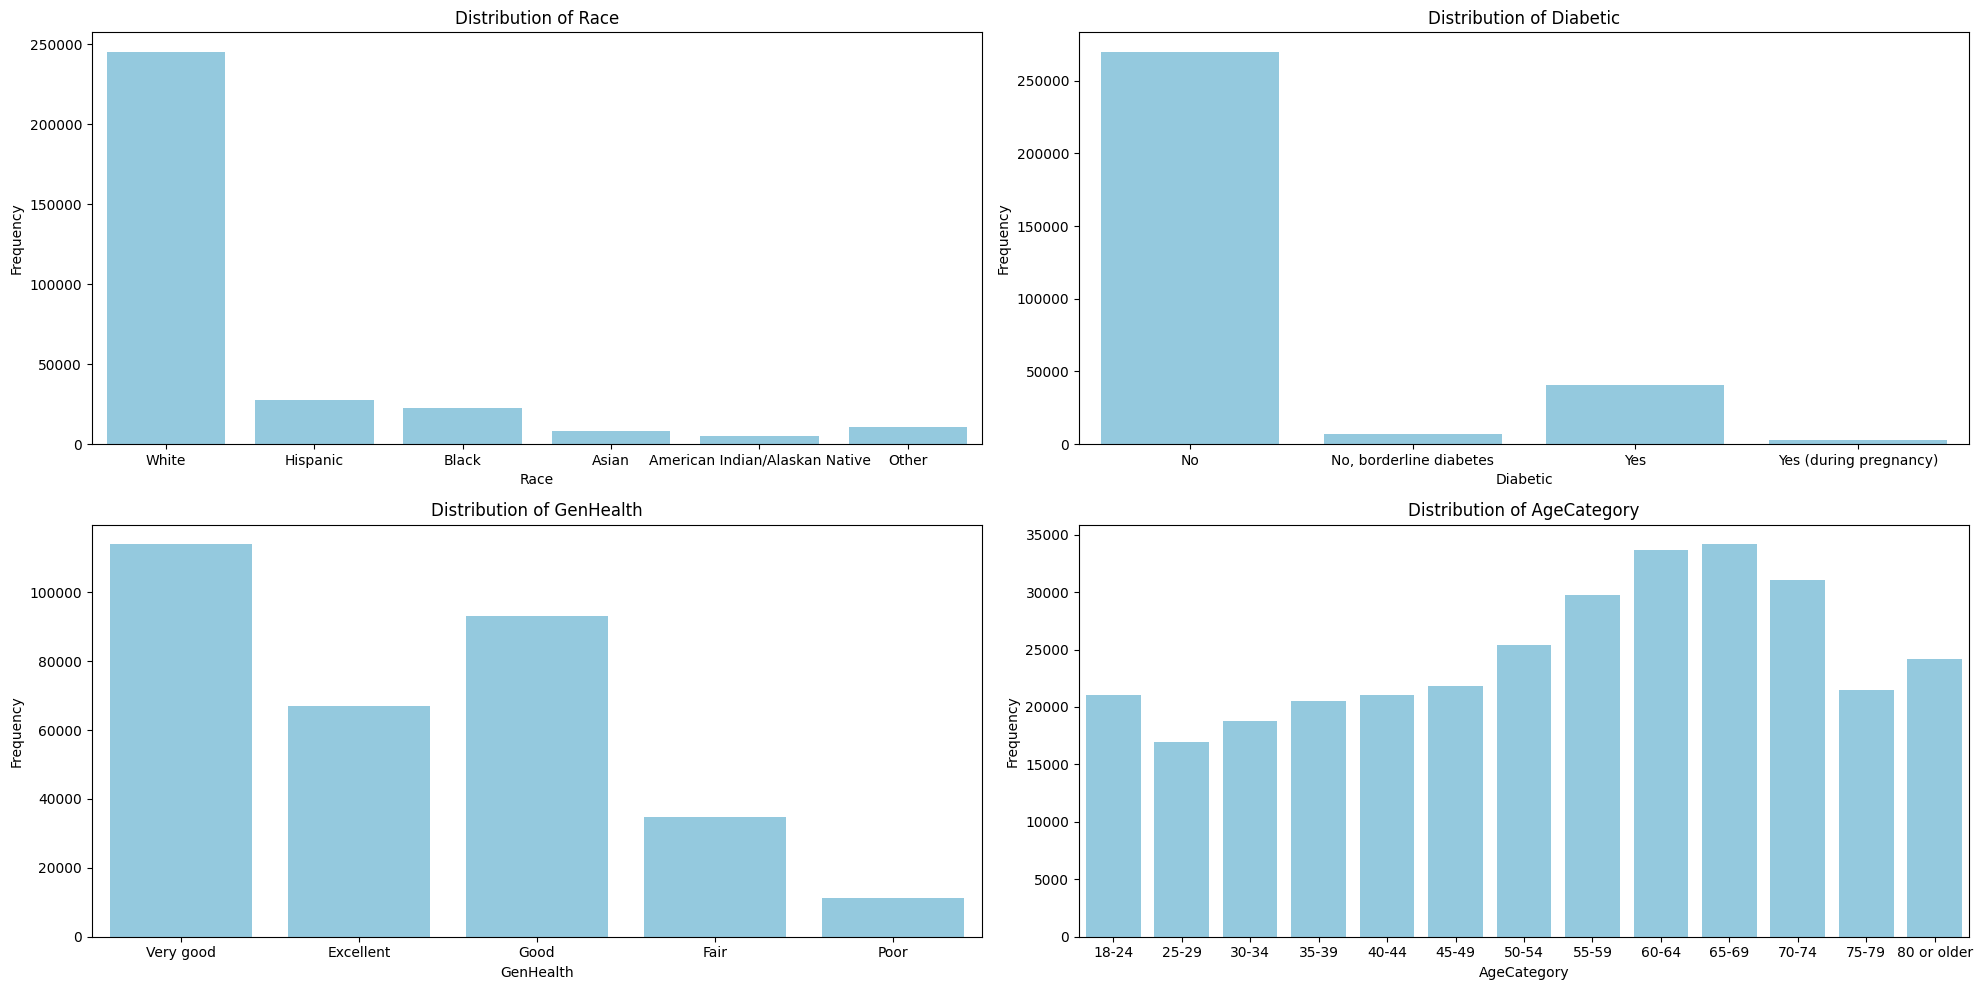

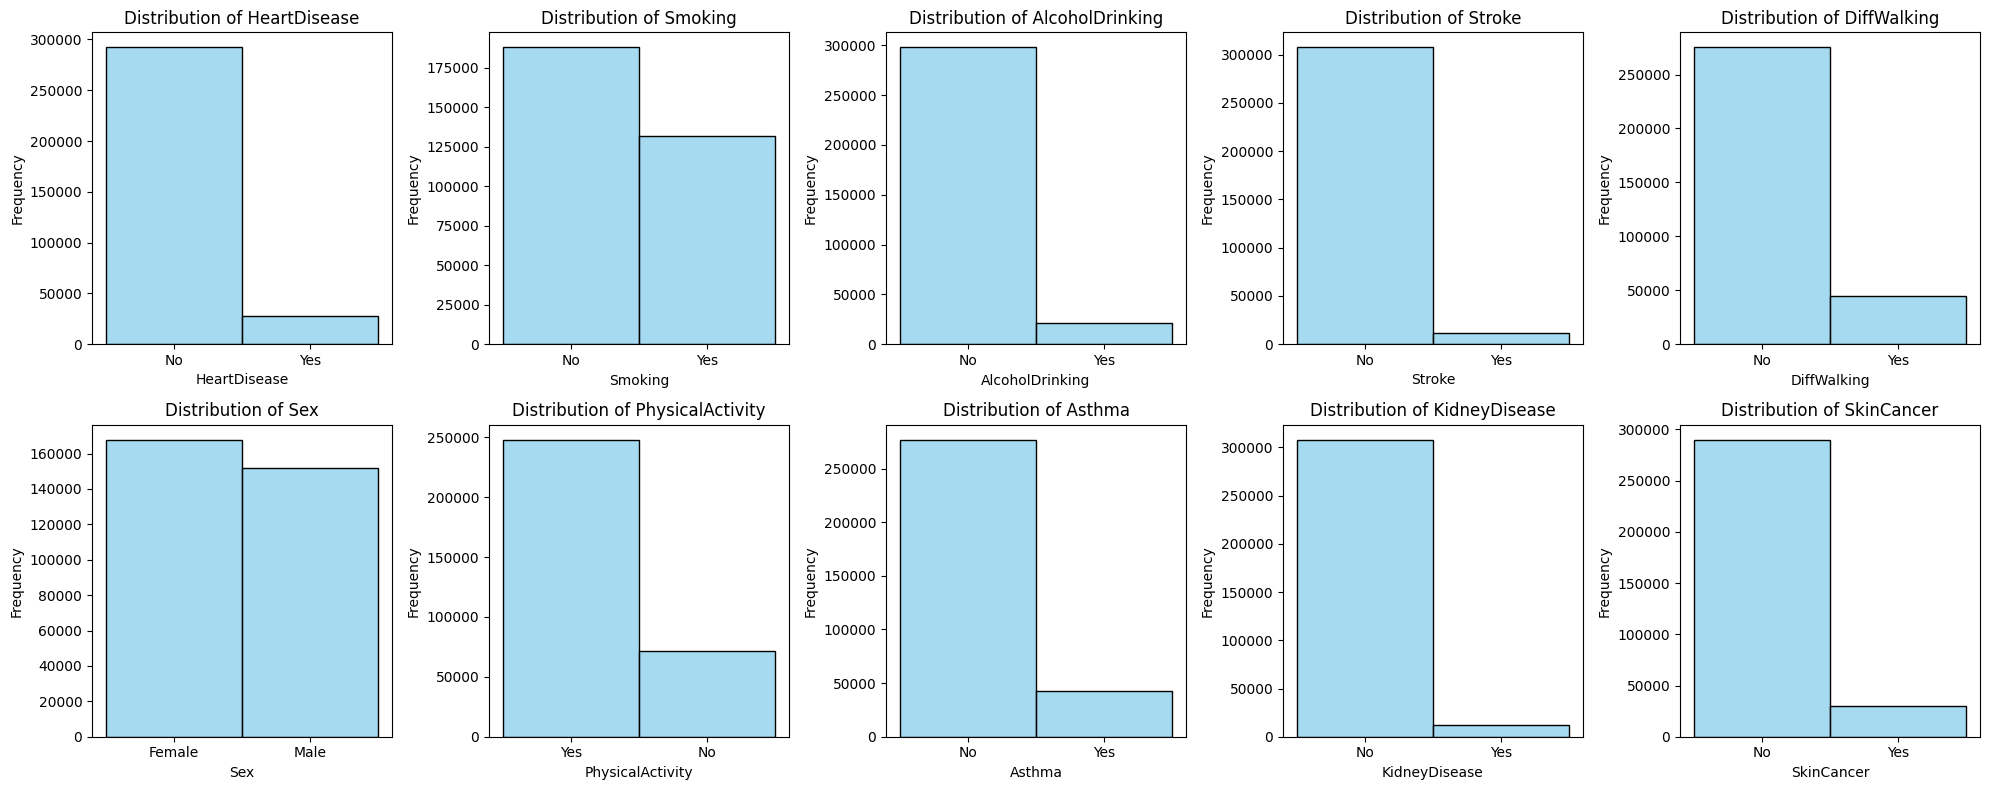

In [5]:
# Age category is listed as a range. Use this function to extract the starting age
def extract_start_age(age_cat):
    return int(age_cat[:2])

df['StartAge'] = df['AgeCategory'].apply(extract_start_age)
df = df.sort_values(by='StartAge')

non_binary_features = ['Race','Diabetic','GenHealth','AgeCategory']
binary_features = [col for col in categorical_features if col not in non_binary_features]

fig, axes = plt.subplots(len(non_binary_features)//2, 2, figsize=(20, 10))
axes = axes.flatten()

for i, feature in enumerate(non_binary_features):
    sns.countplot(data=df, x=feature, color='skyblue', ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(binary_features)//5, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(binary_features):
    sns.histplot(data=df, x=feature, kde=False, color='skyblue', ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [6]:
# Some useful counts
print(f"Proportion who respond yes to physical activity: {len(df[df['PhysicalActivity']=='Yes'])/df.shape[0]:.2f}")
print(f"Proportion who respond yes to never smoking: {len(df[df['Smoking']=='No'])/df.shape[0]:.2f}")
print(f"Male Proportion: {len(df[df['Sex']=='Male'])/df.shape[0]:.2f}")
print(f"NO heart disease: {len(df[df['HeartDisease']=='No'])} and YES heart disease: {len(df[df['HeartDisease']=='Yes'])}")

# distribution of heart disease across different ages

ct = pd.crosstab(original_df['AgeCategory'], original_df['HeartDisease'], normalize='index').multiply(100).round(2)
counts = original_df['AgeCategory'].value_counts()
ct['Distribution'] = counts

print(ct)

Proportion who respond yes to physical activity: 0.78
Proportion who respond yes to never smoking: 0.59
Male Proportion: 0.48
NO heart disease: 292422 and YES heart disease: 27373
HeartDisease     No    Yes  Distribution
AgeCategory                             
18-24         99.38   0.62         21064
25-29         99.22   0.78         16955
30-34         98.79   1.21         18753
35-39         98.56   1.44         20550
40-44         97.69   2.31         21006
45-49         96.59   3.41         21791
50-54         94.55   5.45         25382
55-59         92.60   7.40         29757
60-64         90.12   9.88         33686
65-69         87.99  12.01         34151
70-74         84.40  15.60         31065
75-79         81.15  18.85         21482
80 or older   77.44  22.56         24153


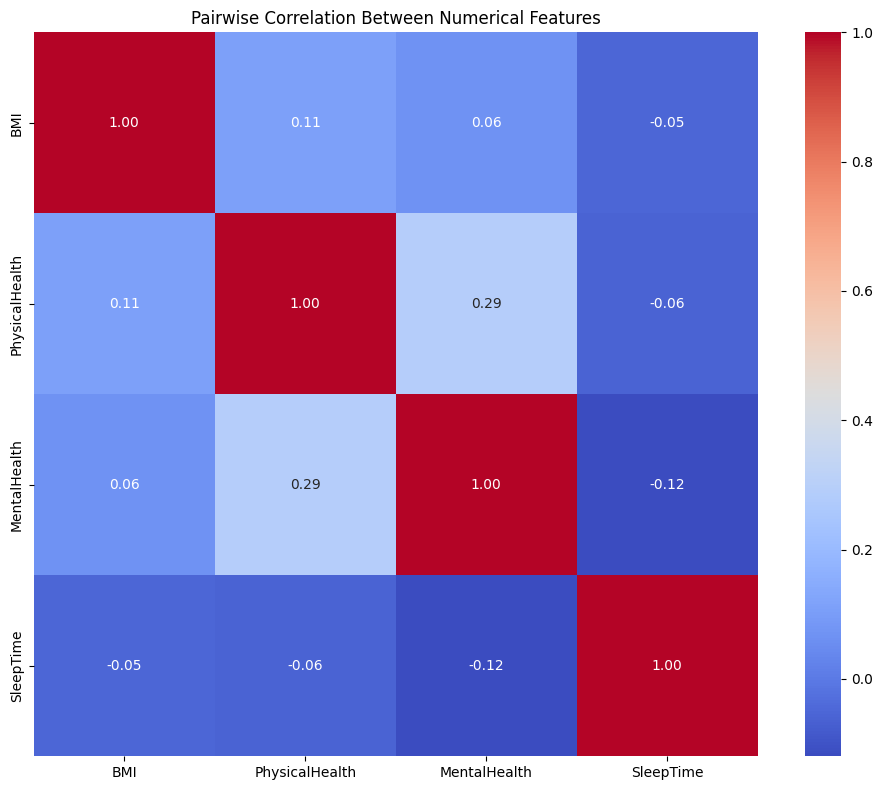

In [7]:
# Correlation matrix for numerical features

corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar=True)
plt.title('Pairwise Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

# Train models

Train different models and assess each for accuracy and fairness.

In [8]:
# encode categorical variables using OrdinalEncoder

from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder()
df[categorical_features] = encoder.fit_transform(df[categorical_features])
# also get the original labels back
labels = encoder.categories_
print(labels)

[array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['Female', 'Male'], dtype=object), array(['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54',
       '55-59', '60-64', '65-69', '70-74', '75-79', '80 or older'],
      dtype=object), array(['American Indian/Alaskan Native', 'Asian', 'Black', 'Hispanic',
       'Other', 'White'], dtype=object), array(['No', 'No, borderline diabetes', 'Yes', 'Yes (during pregnancy)'],
      dtype=object), array(['No', 'Yes'], dtype=object), array(['Excellent', 'Fair', 'Good', 'Poor', 'Very good'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object)]


In [9]:
# imported from ADS

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# accuracy metrics
from sklearn.metrics import precision_score,recall_score
from sklearn.metrics import f1_score

# fairness metrics
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, selection_rate
from fairlearn.metrics import false_negative_rate, false_positive_rate

In [10]:
y=df['HeartDisease']
dropped=df.drop('HeartDisease',axis=1,inplace=False)
X_train, X_test, y_train, y_test=train_test_split(dropped,y,test_size=0.1,random_state=42)

models = [KNeighborsClassifier(), LogisticRegression(), XGBClassifier(),ExtraTreesClassifier()]

for m in models:
    m.fit(X_train, y_train)
    y_pred = m.predict(X_test)

    print(f'model: {str(m)}')
    print(f'Accuracy_score: {accuracy_score(y_test,y_pred):.2f}')
    print(f'Precision_score: {precision_score(y_test,y_pred)}')
    print(f'Recall_score: {recall_score(y_test,y_pred)}')
    print(f'F1-score: {f1_score(y_test,y_pred)}')
    print('-'*30, '\n')

model: KNeighborsClassifier()
Accuracy_score: 0.90
Precision_score: 0.3130311614730878
Recall_score: 0.07923987092147723
F1-score: 0.12646638054363377
------------------------------ 



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


model: LogisticRegression()
Accuracy_score: 0.91
Precision_score: 0.5521739130434783
Recall_score: 0.09107206884187881
F1-score: 0.15635580178516467
------------------------------ 

model: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)
Accuracy_score: 0.91
Precision_score: 0.5456273764258

# Subgroup analysis

Analyze accuracy and fairness across subgroups

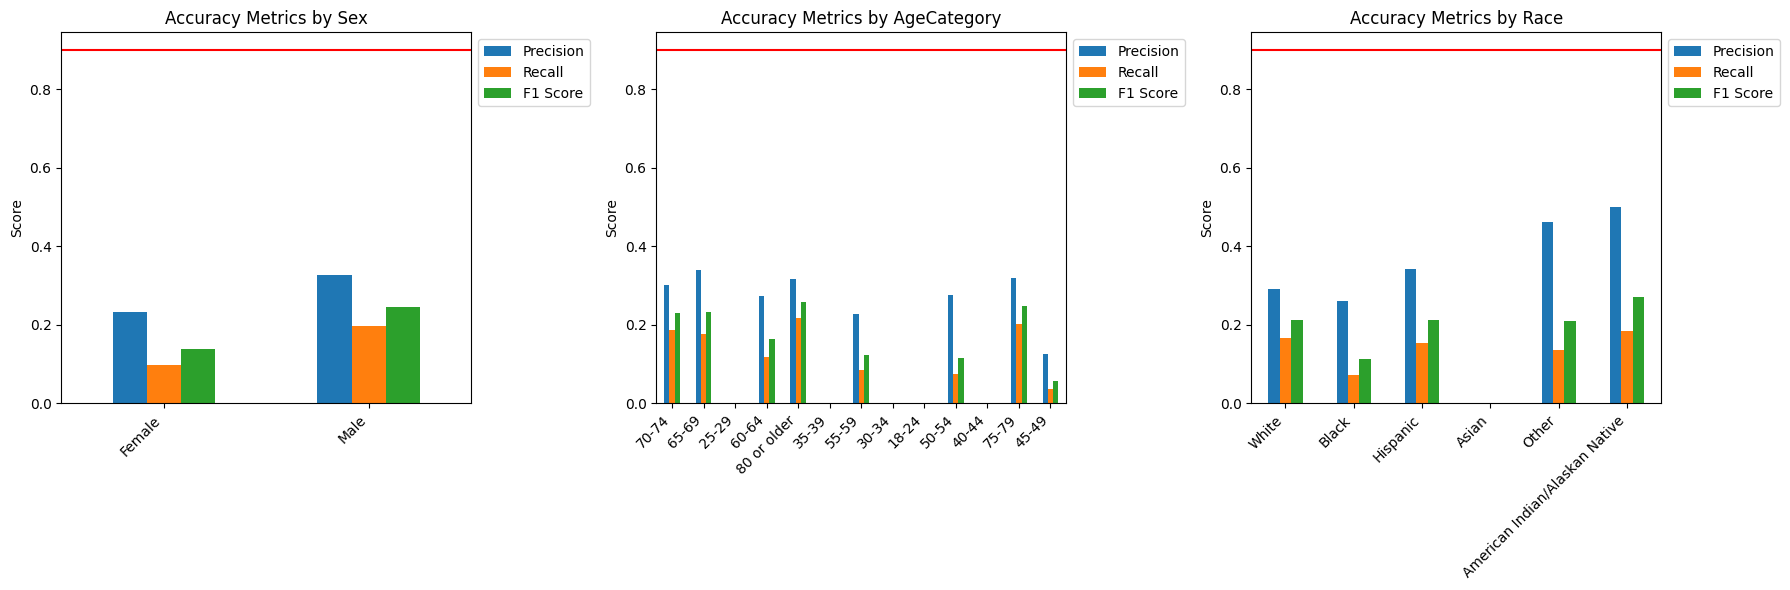

In [11]:
# sensitive attributes: sex, age, race
# subgroup analyze for precision, recall, f1 score

X_test_copy = X_test.copy()
X_test_copy['y_true'] = y_test
X_test_copy['y_pred'] = y_pred

def accuracy_analysis(features):

  fig, axes = plt.subplots(nrows=1, ncols=len(features), figsize=(6*len(features),6))

  for ax, feature in zip(axes,features):

    idx = categorical_features.index(feature) # get feature index in original columns
    original_labels = encoder.categories_[idx] # get the labels in the stored original labels
    metrics_dict = {}

    for val in X_test_copy[feature].unique(): # unique values of each feature
      subgroup = X_test_copy[X_test_copy[feature]==val] # get the subgroup
      label = original_labels[int(val)]
      metrics_dict[label] = {
          'Precision': precision_score(subgroup['y_true'], subgroup['y_pred']),
          'Recall': recall_score(subgroup['y_true'], subgroup['y_pred']),
          'F1 Score': f1_score(subgroup['y_true'], subgroup['y_pred'])
      }

    df = pd.DataFrame(metrics_dict)
    plot = df.T.plot(kind='bar', ax=ax, legend=False)
    ax.set_title(f'Accuracy Metrics by {feature}')
    ax.set_ylabel('Score')
    ax.axhline(y=0.9, color='red', linestyle='-')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.legend(bbox_to_anchor=(1,1)) # move legend to outside the top right.


  plt.tight_layout()
  return fig

fig1 = accuracy_analysis(["Sex","AgeCategory","Race"])
plt.show()

Demographic parity difference (Sex): 0.0380
Demographic parity difference (AgeCategory): 0.1561
Demographic parity difference (Race): 0.0470


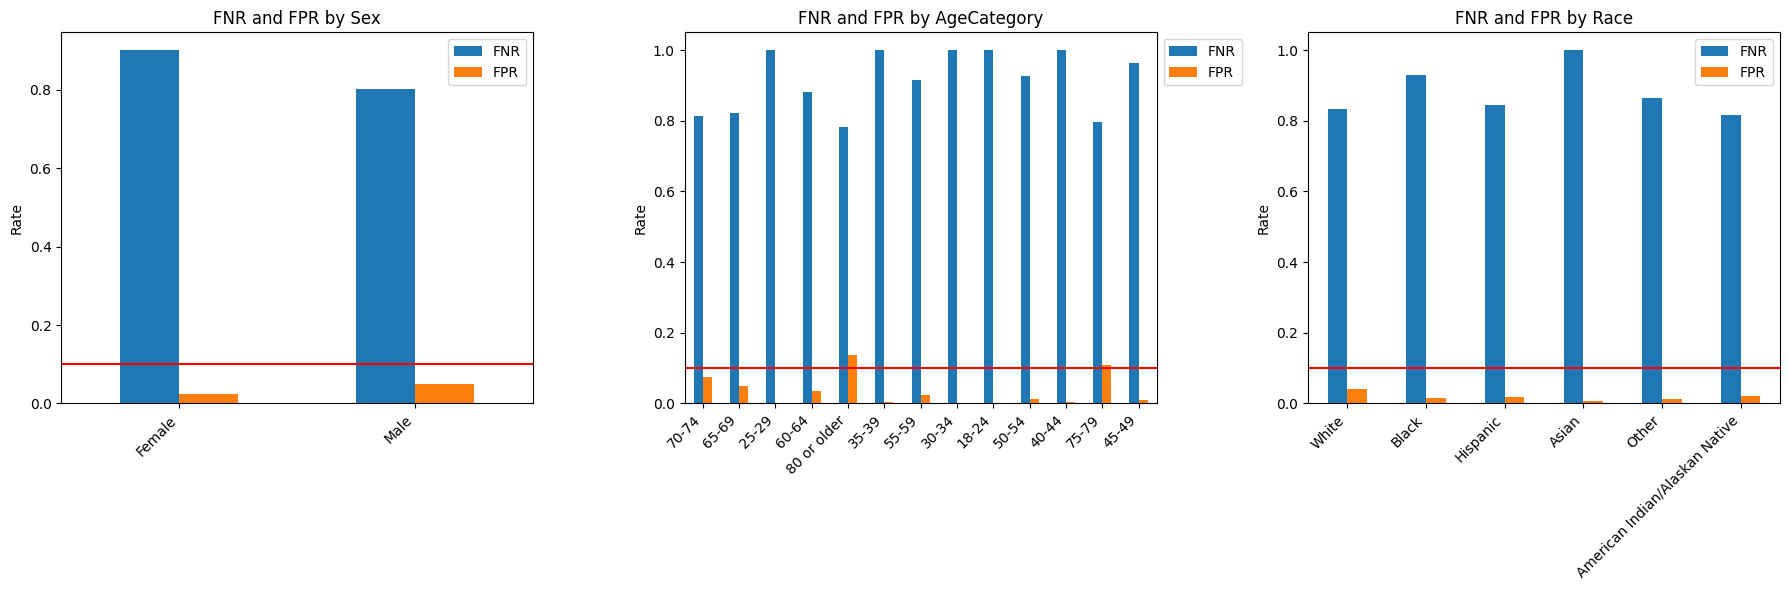

In [12]:
# subgroup analyze for demographic parity difference

from fairlearn.metrics import demographic_parity_difference, false_negative_rate, false_positive_rate

print(f'Demographic parity difference (Sex): {demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Sex"]):.4f}')
print(f'Demographic parity difference (AgeCategory): {demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["AgeCategory"]):.4f}')
print(f'Demographic parity difference (Race): {demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Race"]):.4f}')

def fairness_analysis(features):

  fig, axes = plt.subplots(nrows=1, ncols=len(features), figsize=(6*len(features),6))

  for ax, feature in zip(axes,features):

    idx = categorical_features.index(feature) # get feature index in original columns
    original_labels = encoder.categories_[idx] # get the labels in the stored original labels
    metrics_dict = {}

    for val in X_test_copy[feature].unique(): # unique values of each feature
      subgroup = X_test_copy[X_test_copy[feature]==val] # get the subgroup
      label = original_labels[int(val)]
      metrics_dict[label] = {
          'FNR': false_negative_rate(subgroup['y_true'], subgroup['y_pred']),
          'FPR': false_positive_rate(subgroup['y_true'], subgroup['y_pred'])
      }

    df = pd.DataFrame(metrics_dict)
    plot = df.T.plot(kind='bar', ax=ax)
    ax.set_title(f'FNR and FPR by {feature}')
    ax.set_ylabel('Rate')
    ax.axhline(y=0.1, color='red', linestyle='-')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.legend(bbox_to_anchor=(1,1)) # move legend to outside the top right.

  plt.tight_layout()
  plt.show()

fairness_analysis(["Sex", "AgeCategory","Race"])

In [13]:
seeds = sorted([1, 7, 23, 45, 945, 344, 323, 16080918, 111, 262])
results = {}

for seed in seeds:
  X_train, X_test, y_train, y_test=train_test_split(dropped,y,test_size=0.2,random_state=seed)

  ExtraTreesClassifier().fit(X_train, y_train)
  y_pred = m.predict(X_test)

  results[seed] = {
      'Precision': precision_score(y_test, y_pred),
      'Recall': recall_score(y_test, y_pred),
      'F1 Score': f1_score(y_test, y_pred),
      'FNR': false_negative_rate(y_test, y_pred),
      'FPR': false_positive_rate(y_test, y_pred),
      'Demographic parity difference (Sex)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Sex"]),
      'Demographic parity difference (AgeCategory)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["AgeCategory"]),
      'Demographic parity difference (Race)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Race"])
  }



In [14]:
# print the mean and standard deviation for each metric (across each seed)

results_df = pd.DataFrame(results).T
print(results_df.describe())

       Precision     Recall   F1 Score        FNR        FPR  \
count  10.000000  10.000000  10.000000  10.000000  10.000000   
mean    0.958087   0.880691   0.917755   0.119309   0.003597   
std     0.003028   0.004112   0.002838   0.004112   0.000247   
min     0.952448   0.876745   0.915471   0.109288   0.003264   
25%     0.956563   0.877919   0.916276   0.118447   0.003416   
50%     0.958583   0.879946   0.916602   0.120054   0.003557   
75%     0.960221   0.881553   0.918438   0.122081   0.003736   
max     0.961831   0.890712   0.924906   0.123255   0.004045   

       Demographic parity difference (Sex)  \
count                            10.000000   
mean                              0.036487   
std                               0.002320   
min                               0.032927   
25%                               0.034580   
50%                               0.036437   
75%                               0.038021   
max                               0.039842   

       D

In [15]:
# testing the same seed used in the ADS, but with a 20% test size

X_train, X_test, y_train, y_test=train_test_split(dropped,y,test_size=0.2,random_state=42)

ExtraTreesClassifier().fit(X_train, y_train)
y_pred = m.predict(X_test)

results = {
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred),
    'FNR': false_negative_rate(y_test, y_pred),
    'FPR': false_positive_rate(y_test, y_pred),
    'Demographic parity difference (Sex)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Sex"]),
    'Demographic parity difference (AgeCategory)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["AgeCategory"]),
    'Demographic parity difference (Race)': demographic_parity_difference(y_test,y_pred,sensitive_features=X_test["Race"])
}

print(results)

{'Precision': 0.7439054420093573, 'Recall': 0.5506744440393729, 'F1 Score': 0.6328689640724835, 'FNR': np.float64(0.44932555596062707), 'FPR': np.float64(0.0177859866947138), 'Demographic parity difference (Sex)': np.float64(0.03610598842536007), 'Demographic parity difference (AgeCategory)': np.float64(0.18642539213009013), 'Demographic parity difference (Race)': np.float64(0.05088885162047713)}
